Goals of the notebook:

- Cluster the oligo and opc cells
- Save out labelmat

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import yaml 
from pathlib import Path 

import numpy as np
import pandas as pd
import scanpy as sc
from dotenv import dotenv_values

from hm3d_utils.clustering import run_decomposition

### Data loading and preprocessing

In [3]:
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])
CLUSTERING_DIR = DATADIR / "5_clustering"
MODELDIR = CLUSTERING_DIR / 'all_control'
DATASETS_DIR = MODELDIR / "datasets"


In [4]:
PARAMS_FILE = Path("resources", "clustering_params.yaml")

In [5]:
CELL_TYPE = "Oligo"

if CELL_TYPE == "Neuro":
    adata_fp = DATASETS_DIR / 'neuronal_raw_embed_propagated.h5ad'
else:
    adata_fp = DATASETS_DIR / 'glial_raw_embed_propagated.h5ad'

In [6]:

with open(PARAMS_FILE, "r") as fp:
            parameters = yaml.safe_load(fp)

parameters

{'loop': {'initial_solution_key': 'L1', 'max_levels': 10},
 'neighbors': {'n_neighbors': 15, 'use_rep': 'X_embed'},
 'leiden': {'n_iterations': 5, 'n_jobs': 20, 'n_seeds': 100, 'resolution': []},
 'consensus': {'random_state': 0},
 'pruning': {'max_stratum_size': 10000,
  'min_stratum_size': 10,
  'min_cluster_size': 100,
  'min_marker_genes': 30,
  'symmetric_intermediate_resolution': True,
  'symmetric_highest_resolution': False,
  'min_pct_expression': 0.1,
  'min_specificity': 0.2,
  'min_strata': 2,
  'nn_checks': 2,
  'random_state': 0,
  'significance_threshold': 0.001,
  'strata_key': 'Sample',
  'use_rep': 'X_embed'},
 'masking': {'enabled': False,
  'min_nn_agreement': 0.5,
  'n_neighbors': 40,
  'use_rep': 'X_embed'}}

In [7]:
adata = sc.read_h5ad(adata_fp, backed="r")
if CELL_TYPE == "Neuro":
    load_mask = adata.obs.IsControl
else:
    load_mask = (adata.obs["major_features_propagated"].str.contains(CELL_TYPE)) & (adata.obs.IsControl)

adata = adata[load_mask].to_memory()

adata.obs["L1"] = adata.obs.major_features_propagated.copy()
# Remove excluded genes
adata = adata[:, ~adata.var.IsHvgExcludedGene]

sc.pp.normalize_total(adata, target_sum=10_000)

/REDACTED-path/HypoMap3D/.venv/lib/python3.11/site-packages/scanpy/preprocessing/_normalization.py:269: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


In [8]:
# for later plotting of genes
adata.layers["log1p"] = adata.X.copy()
sc.pp.log1p(adata, layer="log1p")

In [9]:
adata

AnnData object with n_obs × n_vars = 142731 × 55371
    obs: 'CellID', 'Dataset', 'Sample', 'total_counts', 'n_genes', 'pct_mito', 'Author', 'Source', 'Data_source_link', 'GEO', 'Publication_Link', 'Suspension', 'Technology', 'Author_Sex_harmonized', 'Strain', 'Diet', 'Treatment', 'Age', 'Mean_age_in_weeks', 'IsControl', 'cluster_id_label', 'supertype_id_label', 'subclass_id_label', 'class_id_label', 'C66_named', 'C185_named', 'C286_named', 'C465_named', 'ABC_class_propagated', 'ABC_class_confidence', 'to_be_removed', 'IsNeuronal', 'major_features', 'major_features_propagated', 'major_features_confidence', 'ABC_supertype_propagated', 'ABC_supertype_confidence', 'ABC_subclass_propagated', 'ABC_subclass_confidence', 'ABC_cluster_propagated', 'ABC_cluster_confidence', 'L1'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTFOrtholog', 'IsSourceGene', 'IsTargetGene', 'IsHvgExcludedGene', 'IsAnnotationExcludedGene', 'IsPriorityGene', 'IsTopGene', 'IsHvg'
    uns: 'neighbors', 'tsne', 'umap', 'log1p

### Decomposing L1

In [10]:
for res in [0.08]: 

    labelmat = run_decomposition(
        adata,
        use_rep = parameters["neighbors"]["use_rep"],
        init_key = parameters["loop"]["initial_solution_key"],
        max_levels = 1,
        n_neighbors = parameters["neighbors"]["n_neighbors"],
        resolutions = [res],
        n_seeds = parameters["leiden"]["n_seeds"],
        n_iterations = parameters["leiden"]["n_iterations"],
        n_jobs = parameters["leiden"]["n_jobs"],
        strata_key = parameters["pruning"]["strata_key"],
        nn_checks = parameters["pruning"]["nn_checks"],
        min_cluster_size = parameters["pruning"]["min_cluster_size"],
        min_stratum_size = parameters["pruning"]["min_stratum_size"],
        max_stratum_size = parameters["pruning"]["max_stratum_size"],
        min_strata = parameters["pruning"]["min_strata"],
        min_pct_expression = parameters["pruning"]["min_pct_expression"],
        min_specificity = parameters["pruning"]["min_specificity"],
        significance_threshold = parameters["pruning"]["significance_threshold"],
        min_marker_genes = parameters["pruning"]["min_marker_genes"],
        symmetric = parameters["pruning"]["symmetric_intermediate_resolution"],
        masking_enabled = parameters["masking"]["enabled"],
        min_nn_agreement = parameters["masking"]["min_nn_agreement"],
        random_state = parameters["pruning"]["random_state"]
    )

    labelmat = pd.Series(labelmat[:, -1], index=adata.obs.index).replace('-1', pd.NA).astype("category")

    adata.obs[f"L2_new_{res}"] = labelmat


0 and 6 merged due to insufficient valid overlapping strata.
	>>6 and 0 merged to make 6_0
2 vs 6_0 passed with 1425 vs 741 markers
1 vs 5 passed with 1208 vs 1034 markers
5 vs 6_0 passed with 1989 vs 576 markers
1 vs 2 passed with 533 vs 405 markers
4 and 5 merged due to insufficient valid overlapping strata.
	>>5 and 4 merged to make 5_4
1 vs 5_4 passed with 1195 vs 1008 markers
6_0 vs 5_4 passed with 579 vs 1947 markers
2 or 3 merged due to insufficient cluster size 775/26.
	>>3 and 2 merged to make 3_2
6_0 vs 3_2 passed with 742 vs 1447 markers
1 vs 3_2 passed with 533 vs 403 markers
Step finished with  0.00% of obs locked and 4 clusters.                                                                                           


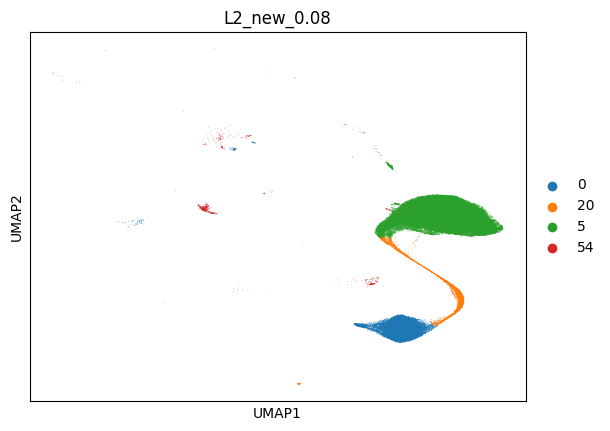

In [11]:
final_l2_col = "L2_new_0.08"
sc.pl.umap(adata, color=[final_l2_col], ncols=1)

there appears to be a low quality cluster that can be removed later

### Decomposing level 2

In [12]:

for res in [0.05]: 

    labelmat = run_decomposition(
        adata,
        use_rep = parameters["neighbors"]["use_rep"],
        init_key = final_l2_col,
        max_levels = 10,
        n_neighbors = parameters["neighbors"]["n_neighbors"],
        resolutions = [res],
        n_seeds = parameters["leiden"]["n_seeds"],
        n_iterations = parameters["leiden"]["n_iterations"],
        n_jobs = parameters["leiden"]["n_jobs"],
        strata_key = parameters["pruning"]["strata_key"],
        nn_checks = parameters["pruning"]["nn_checks"],
        min_cluster_size = parameters["pruning"]["min_cluster_size"],
        min_stratum_size = parameters["pruning"]["min_stratum_size"],
        max_stratum_size = parameters["pruning"]["max_stratum_size"],
        min_strata = parameters["pruning"]["min_strata"],
        min_pct_expression = parameters["pruning"]["min_pct_expression"],
        min_specificity = parameters["pruning"]["min_specificity"],
        significance_threshold = parameters["pruning"]["significance_threshold"],
        min_marker_genes = parameters["pruning"]["min_marker_genes"],
        symmetric = parameters["pruning"]["symmetric_intermediate_resolution"],
        masking_enabled = parameters["masking"]["enabled"],
        min_nn_agreement = parameters["masking"]["min_nn_agreement"],
        random_state = parameters["pruning"]["random_state"],
        level=1 # start at level idx 1 as you have decomposed the 0th level before
    )

    labelmat = pd.Series(labelmat[:, -1], index=adata.obs.index).replace('-1', pd.NA).astype("category")

    adata.obs[f"L3_new_{res}"] = labelmat


0 and 1 merged due to insufficient valid overlapping strata.
	>>1 and 0 merged to make 1_0
0 and 2 merged due to insufficient valid overlapping strata.
	>>2 and 0 merged to make 2_0
1 vs 2_0 passed with 777 vs 382 markers
0 vs 1 FAILED with 12 vs 907 markers
	>>1 and 0 merged to make 1_0
1 or 2 merged due to insufficient cluster size 69/607.
	>>2 and 1 merged to make 2_1
0 vs 2_1 FAILED with 14 vs 0 markers
	>>2_1 and 0 merged to make 2_1_0
Step finished with  94.28% of obs locked and 5 clusters.                                                                                           
0 vs 1 passed with 425 vs 454 markers
1 and 2 merged due to insufficient valid overlapping strata.
	>>2 and 1 merged to make 2_1
0 vs 2_1 passed with 416 vs 440 markers
Step finished with  95.66% of obs locked and 6 clusters.                                                                                           
0 and 1 merged due to insufficient valid overlapping strata.
	>>1 and 0 merged to make 1_0

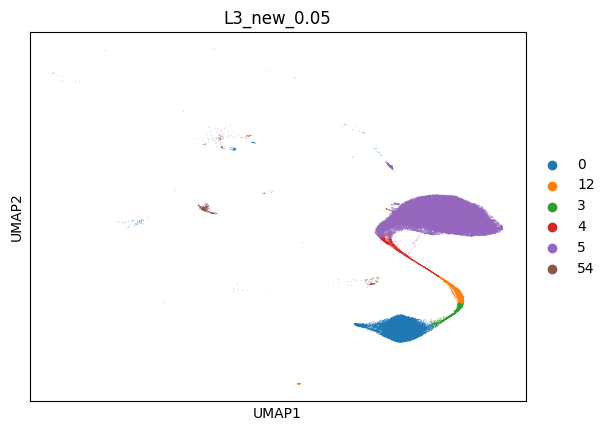

In [13]:
final_l3_col = "L3_new_0.05"
sc.pl.umap(adata, color=[final_l3_col], ncols=1)

### Decomposing L3

Allowing for asymmetric marker genes during pruning.

In [14]:
symmetric = parameters["pruning"]["symmetric_highest_resolution"]

for res in [0.075]: 

    labelmat = run_decomposition(
        adata,
        use_rep = parameters["neighbors"]["use_rep"],
        init_key = final_l3_col,
        max_levels = 20,
        n_neighbors = parameters["neighbors"]["n_neighbors"],
        resolutions = [res],
        n_seeds = parameters["leiden"]["n_seeds"],
        n_iterations = parameters["leiden"]["n_iterations"],
        n_jobs = parameters["leiden"]["n_jobs"],
        strata_key = parameters["pruning"]["strata_key"],
        nn_checks = parameters["pruning"]["nn_checks"],
        min_cluster_size = parameters["pruning"]["min_cluster_size"],
        min_stratum_size = parameters["pruning"]["min_stratum_size"],
        max_stratum_size = parameters["pruning"]["max_stratum_size"],
        min_strata = parameters["pruning"]["min_strata"],
        min_pct_expression = parameters["pruning"]["min_pct_expression"],
        min_specificity = parameters["pruning"]["min_specificity"],
        significance_threshold = parameters["pruning"]["significance_threshold"],
        min_marker_genes = parameters["pruning"]["min_marker_genes"],
        symmetric = symmetric,
        masking_enabled = parameters["masking"]["enabled"],
        min_nn_agreement = parameters["masking"]["min_nn_agreement"],
        random_state = parameters["pruning"]["random_state"],
        level=11 # start at level idx 11 as you have decomposed up to 10th level before
    )

    labelmat = pd.Series(labelmat[:, -1], index=adata.obs.index).replace('-1', pd.NA).astype("category")

    adata.obs[f"L4_new_{res}_asym"] = labelmat


0 and 1 merged due to insufficient valid overlapping strata.
	>>1 and 0 merged to make 1_0
2 vs 1_0 passed with 614 markers
1 or 2 merged due to insufficient cluster size 607/69.
	>>2 and 1 merged to make 2_1
0 vs 2_1 FAILED with 14 markers
	>>2_1 and 0 merged to make 2_1_0
0 vs 1 passed with 899 markers
0 or 2 merged due to insufficient cluster size 31391/82.
	>>2 and 0 merged to make 2_0
1 vs 2_0 passed with 901 markers
0 and 1 merged due to insufficient valid overlapping strata.
	>>1 and 0 merged to make 1_0
Step finished with  6.28% of obs locked and 8 clusters.                                                                                           
0 or 1 merged due to insufficient cluster size 91/1537.
	>>1 and 0 merged to make 1_0
0 or 1 merged due to insufficient cluster size 31390/83.
	>>1 and 0 merged to make 1_0
0 and 1 merged due to insufficient valid overlapping strata.
	>>1 and 0 merged to make 1_0
Step finished with  100.00% of obs locked and 8 clusters.               

In [ ]:
final_l4_col = "L4_new_0.075_asym"

The one small cluster we got at the beginning looks quite fishy. 

It has quite high Rbfox3 expression, increasing the probability of it being a doublet cluster, leading to its removal here.

In [17]:
helper_adata = sc.read_h5ad(adata_fp, backed="r") # loading this because Rbfox3 had been removed from adata via IsExcludedHvg
load_mask = (helper_adata.obs["major_features_propagated"].str.contains(CELL_TYPE)) & (helper_adata.obs.IsControl)
helper_adata = helper_adata[load_mask].to_memory()
sc.pp.normalize_total(helper_adata, target_sum=10_000)
sc.pp.log1p(helper_adata)

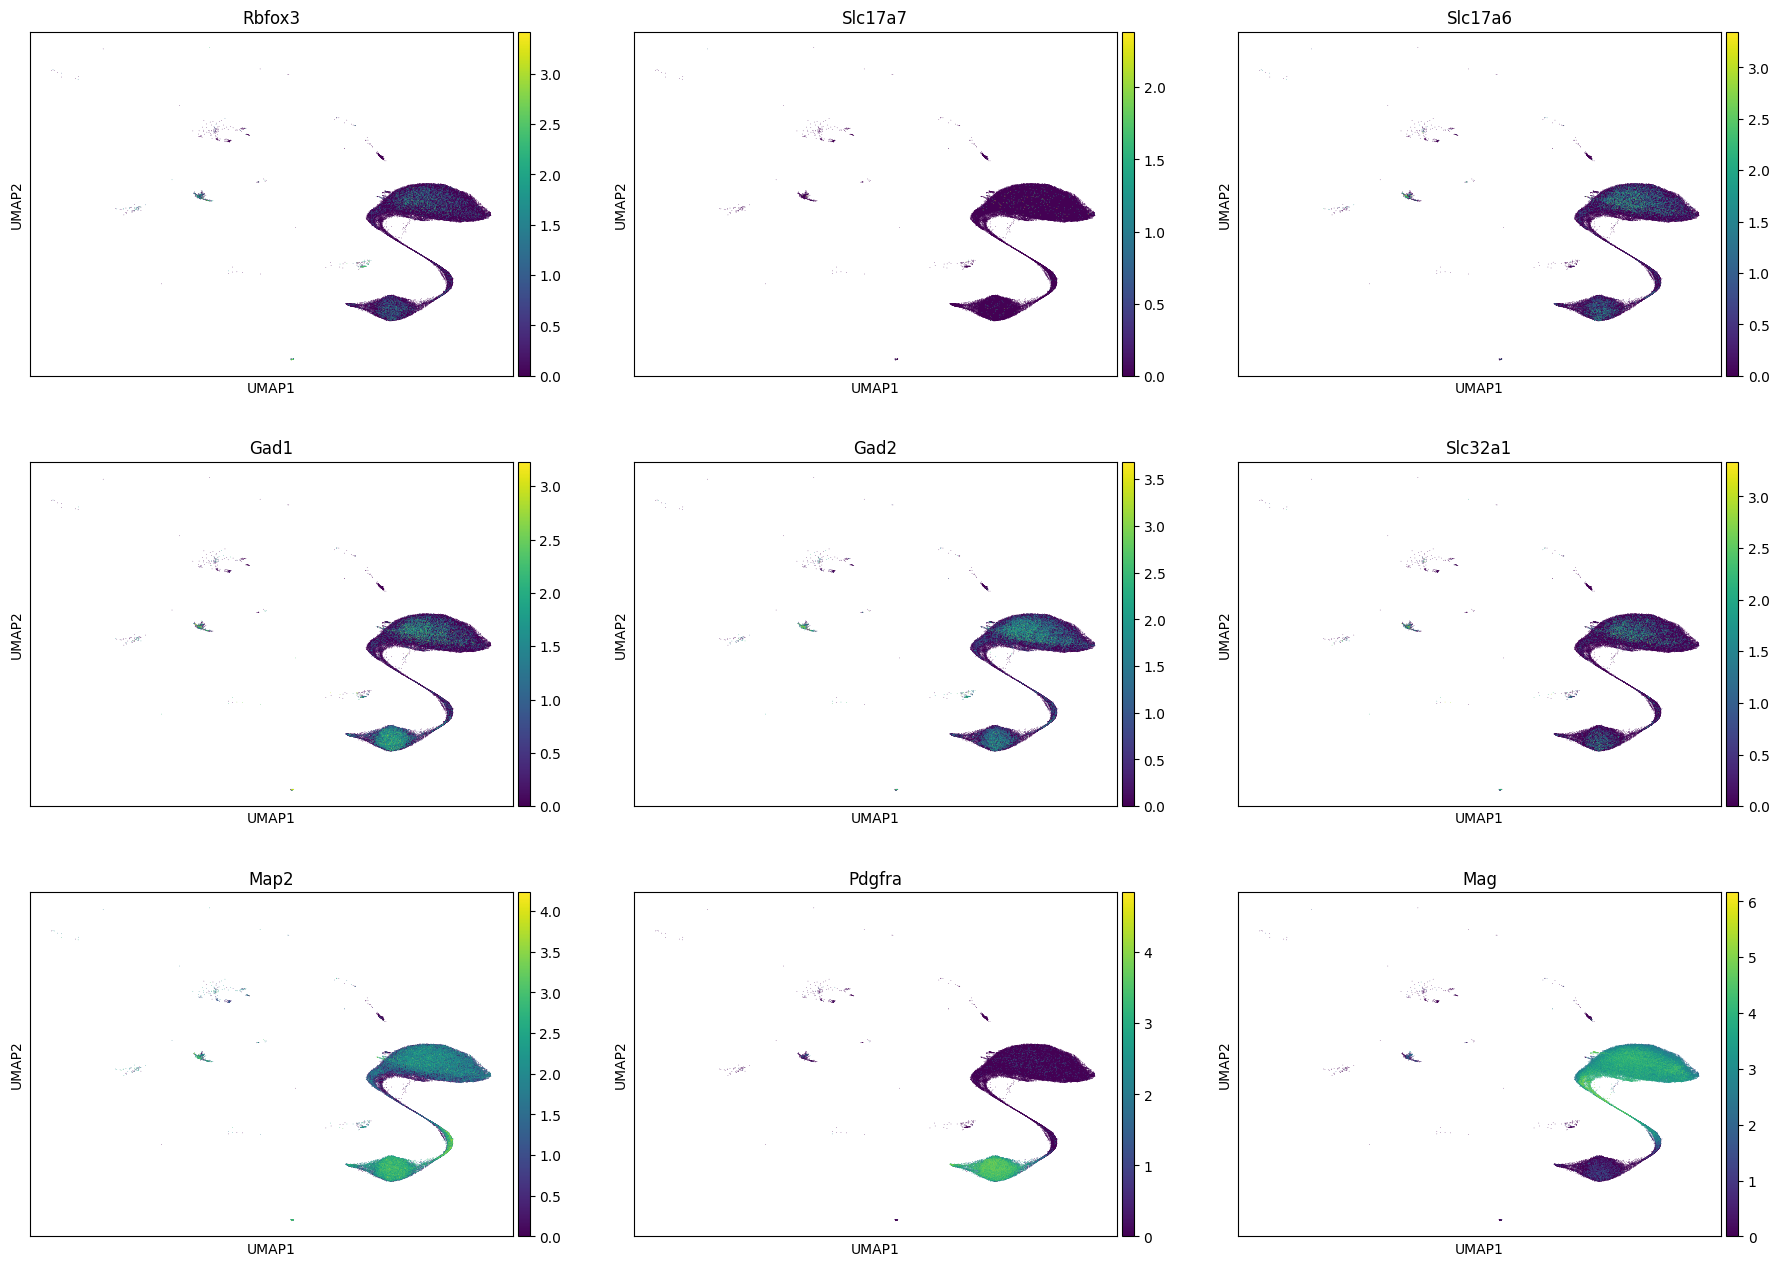

In [18]:
sc.pl.umap(helper_adata, color = ["Rbfox3", "Slc17a7", "Slc17a6", "Gad1", "Gad2", "Slc32a1", "Map2","Pdgfra", "Mag"],ncols=3, )

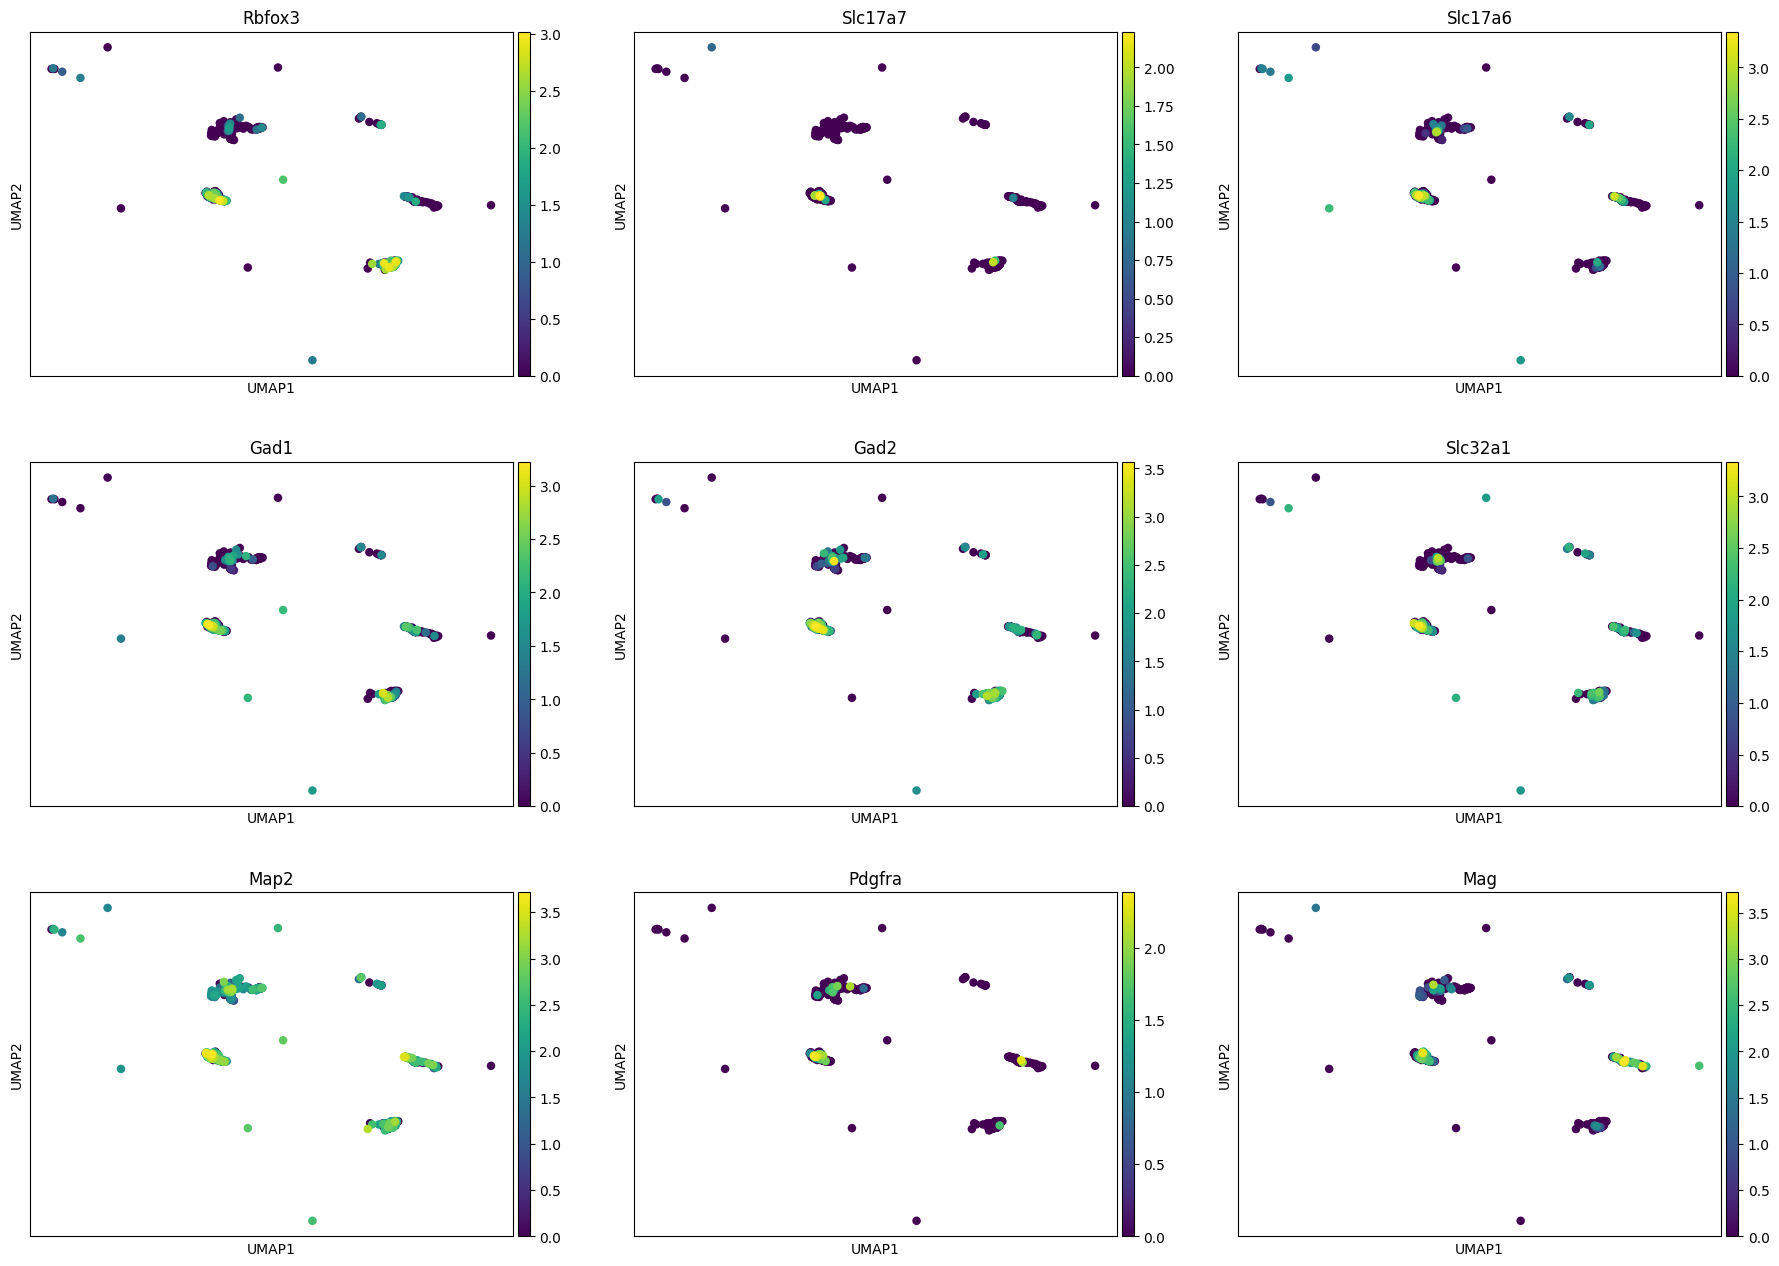

In [19]:
sc.pl.umap(helper_adata[adata.obs[final_l2_col] == "54"], color = ["Rbfox3", "Slc17a7", "Slc17a6", "Gad1", "Gad2", "Slc32a1", "Map2","Pdgfra", "Mag"],ncols=3, )

In [23]:
adata.obs.loc[adata.obs[final_l2_col] == "54", final_l2_col] = np.nan
adata.obs.loc[adata.obs[final_l3_col] == "54", final_l3_col] = np.nan
adata.obs.loc[adata.obs[final_l4_col] == "54", final_l4_col] = np.nan

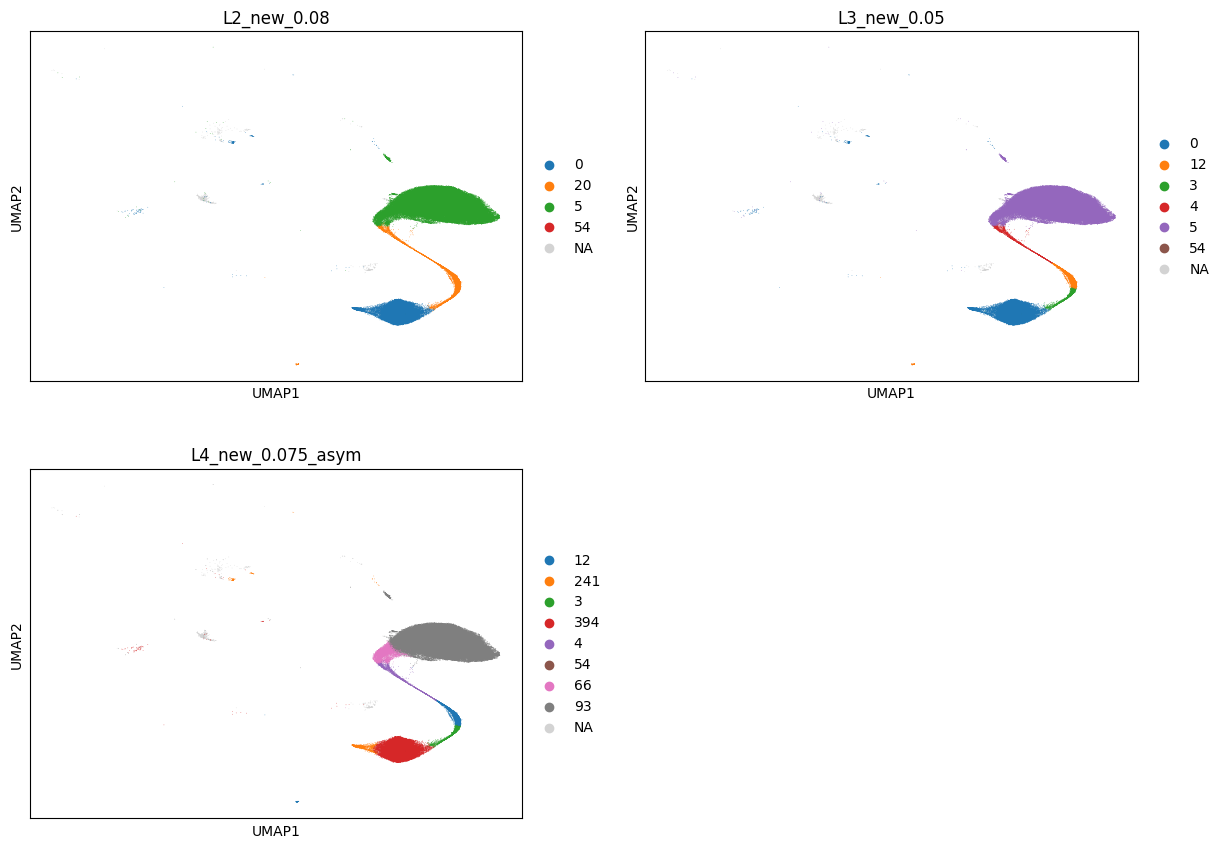

In [24]:
sc.pl.umap(adata, color=[final_l2_col,final_l3_col, final_l4_col, ], ncols=2)

### Let's save out the labelmat

In [25]:
final_labelmat = adata.obs.loc[:, [final_l2_col, final_l3_col, final_l4_col]]
final_labelmat.columns=["L2", "L3", "L4"]
final_labelmat.head()

,L2,L3,L4
SC1-01_SAMN18754353_AAACGCTTCTGGCCAG,0,0,394
SC1-01_SAMN18754353_AAAGGGCCACAACATC,NaN,NaN,NaN
SC1-01_SAMN18754353_AAAGGGCGTCGCTTAA,0,0,394
SC1-01_SAMN18754353_AAAGTCCTCATTTGGG,0,0,394
SC1-01_SAMN18754353_AAAGTCCTCTGGGCCA,5,5,93


In [96]:
#final_labelmat.to_csv(CLUSTERING_DIR / "oligo_labelmat.csv")